In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

In [20]:
import os
from torchvision.datasets import CelebA
# monkey patch to skip integrity check
CelebA._check_integrity = lambda self: True

# https://www.kaggle.com/datasets/jessicali9530/celeba-dataset?resource=download
data_path = "./data/celeba"
if os.path.exists(data_path):
    print(f"Index found at {data_path}, attempting to load locally...")
    do_download = False
else:
    print(f"Data not found at {data_path}, attempting download...")
    do_download = True

# 2. Define Transforms
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# 3. Load Dataset
try:
    # Ensure data is in ./data/celeba/ 
    # e.g. ./data/celeba/img_align_celeba.zip
    train_dataset = datasets.CelebA(root="./data", split='train', target_type='attr', download=do_download, transform=transform)
    test_dataset  = datasets.CelebA(root="./data", split='test', target_type='attr', download=do_download, transform=transform)

except RuntimeError as e:
    print("\nError loading dataset. Torchvision expects the following structure:")
    print(" ./data/celeba/")
    print("    ├── img_align_celeba.zip")
    print("    ├── list_attr_celeba.txt")
    print("    ├── list_eval_partition.txt")
    print("    └── ... (other metadata files)")
    raise e

# Attribute 15 (Eyeglasses)
attr_idx = 15 
print("Filtering training data for Eyeglasses...")

idx_train_1 = torch.where(train_dataset.attr[:, attr_idx] == 1)[0].tolist()
train_1 = Subset(train_dataset, idx_train_1)
train_loader = DataLoader(train_1, batch_size=128, shuffle=True)

print(f"Training samples (Wearing Glasses): {len(train_1)}")
print(f"Total test samples: {len(test_dataset)}")

Index found at ./data/celeba, attempting to load locally...
Filtering training data for Eyeglasses...
Training samples (Wearing Glasses): 10521
Total test samples: 19962


In [21]:
from torch.utils.data import Subset, DataLoader
import random

# "Normal" = With Glasses (1)
# "Anomaly" = No Glasses (0)
attr_idx = 15

idx_test_1 = torch.where(test_dataset.attr[:, attr_idx] == 1)[0].tolist()
idx_test_not1 = torch.where(test_dataset.attr[:, attr_idx] == 0)[0].tolist()

print("Test (Glasses):", len(idx_test_1))
print("Test (No Glasses):", len(idx_test_not1))

# Balance the test set
# cap it at 2000 to keep evaluation fast
N = min(len(idx_test_1), len(idx_test_not1))
N = min(N, 2000) 
random.shuffle(idx_test_1)
random.shuffle(idx_test_not1)

# Combine: N normals + N anomalies
balanced_indices = idx_test_1[:N] + idx_test_not1[:N]
test_balanced = Subset(test_dataset, balanced_indices)
test_loader = DataLoader(test_balanced, batch_size=256, shuffle=True)

print(f"Balanced test set size: {len(test_balanced)}")

Test (Glasses): 1289
Test (No Glasses): 18673
Balanced test set size: 2578


In [24]:
class Encoder(nn.Module):
  class AddGaussianNoise(nn.Module):
    def __init__(self, mean=0.0, std=0.05):
        super().__init__()
        self.mean = mean
        self.std = std

    def forward(self, x):
        if not self.training:
            return x
        return x + torch.randn_like(x) * self.std + self.mean

  def __init__(self):
    super().__init__()

    # Regularization
    self.noise = self.AddGaussianNoise(0.0, 0.15)

    self.feature_extractor = nn.Sequential(
      # 1 -> 3 channels for CelebA
      nn.Conv2d(3, 32, 4, stride=2, padding=1),
      nn.ReLU(),
      nn.Conv2d(32, 64, 4, stride=2, padding=1),
      nn.ReLU(),
      nn.Conv2d(64, 128, 3, stride=1, padding=0),
      nn.ReLU(),
    )

    self.pool = nn.AdaptiveAvgPool2d((1, 1))
    
    # 128 channels come out of the last conv layer
    self.fc = nn.Linear(128, 32)

  def forward(self, x):
    x = self.noise(x)
    x = self.feature_extractor(x)
    x = self.pool(x)
    x = x.view(x.size(0), -1)
    return self.fc(x)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = Encoder().to(device)

In [25]:
def compute_center(loader):
  model.eval()
  c = torch.zeros(32, device=device)
  n = 0

  with torch.no_grad():
    for x, _ in loader:
      x = x.to(device)
      z = model(x)
      c += z.sum(0)
      n += z.size(0)

  return c / n

c = compute_center(train_loader)

In [26]:
nu = 0.1
R = torch.tensor(0.0, device=device, requires_grad=True)

def svdd_loss(z, c, R):
  dist = torch.sum((z - c)**2, dim=1)
  score = dist - R**2
  hinge = torch.maximum(score, torch.zeros_like(score))
  return R**2 + (1/nu) * torch.mean(hinge), dist.mean()

In [28]:
optimizer = optim.Adam(
    list(model.parameters()) + [R],
    lr=1e-4,
    weight_decay=1e-6
)

criterion = lambda z: svdd_loss(z, c, R)

epochs = 25
loss_history = []

# some warmup
for epoch in range(5):
  model.train()
  running_loss = 0
  for x, _ in train_loader:
    x = x.to(device)

    optimizer.zero_grad()
    z = model(x)
    loss, dist_mean = criterion(z)
    loss.backward()
    optimizer.step()

c = compute_center(train_loader)

for epoch in range(epochs):
  model.train()
  running_loss = 0

  for x, _ in train_loader:
    x = x.to(device)

    optimizer.zero_grad()
    z = model(x)
    loss, dist_mean = criterion(z)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * x.size(0)

  epoch_loss = running_loss / len(train_1)
  loss_history.append(epoch_loss)
  print(f"Epoch {epoch+1}/{epochs} — Loss: {epoch_loss}")

Epoch 1/25 — Loss: 8.727835211218484e-05
Epoch 2/25 — Loss: 6.930993479080604e-05
Epoch 3/25 — Loss: 6.260234704067546e-05
Epoch 4/25 — Loss: 5.579744300475692e-05
Epoch 5/25 — Loss: 5.2684371014455695e-05
Epoch 6/25 — Loss: 4.735074617132306e-05
Epoch 7/25 — Loss: 4.3295750481874614e-05
Epoch 8/25 — Loss: 4.0267180801822386e-05
Epoch 9/25 — Loss: 3.859883556228148e-05
Epoch 10/25 — Loss: 3.533204673030706e-05
Epoch 11/25 — Loss: 3.223725519329579e-05
Epoch 12/25 — Loss: 3.108999343462607e-05
Epoch 13/25 — Loss: 2.943104831236972e-05
Epoch 14/25 — Loss: 2.6904306829573368e-05
Epoch 15/25 — Loss: 2.5278385472905234e-05
Epoch 16/25 — Loss: 2.41990954025207e-05
Epoch 17/25 — Loss: 2.3085959135584296e-05
Epoch 18/25 — Loss: 2.2068714550150863e-05
Epoch 19/25 — Loss: 2.0566594001639277e-05
Epoch 20/25 — Loss: 1.955545882692166e-05
Epoch 21/25 — Loss: 1.8439977704738937e-05
Epoch 22/25 — Loss: 1.7492762704594307e-05
Epoch 23/25 — Loss: 1.690804814017995e-05
Epoch 24/25 — Loss: 1.562469144479

In [29]:
import joblib

joblib.dump(model, "model.joblib")

['model.joblib']

In [33]:
def anomaly_scores(loader):
  scores = []
  labels = []
  model.eval()
  with torch.no_grad():
    for x, y in loader:
      x = x.to(device)
      z = model(x)
      dist = torch.sum((z - c)**2, dim=1)
      scores.extend(dist.cpu().numpy())
      
      # only the column (idx 15)
      # y has shape [Batch, 40]
      labels.extend(y[:, 15].cpu().numpy())
      
  return np.array(scores), np.array(labels)
scores, labels = anomaly_scores(test_loader)

In [34]:
print(scores)

[1.7702905e-06 3.8876078e-06 3.6555057e-06 ... 4.6070618e-06 3.1230261e-06
 2.2606391e-06]


In [ ]:
from sklearn.metrics import roc_auc_score

y_true_anomaly = (labels == 0) # 1 if anomaly, 0 if normal
auc = roc_auc_score(y_true_anomaly, scores)
print("AUROC (Detection of No-Glasses):", auc)

AUROC (Detection of No-Glasses): 0.47173102235842945


In [36]:
fpr, tpr, thresholds = roc_curve(labels == 1, -scores)
J = tpr - fpr
best_thresh = thresholds[np.argmax(J)]

In [37]:
best_thresh

np.float32(-1.9562242e-06)

In [38]:
pred_is_1 = (-scores) > best_thresh
accuracy = np.mean(pred_is_1 == (labels == 1))
print("Fixed Accuracy:", accuracy)

Fixed Accuracy: 0.5019394879751745


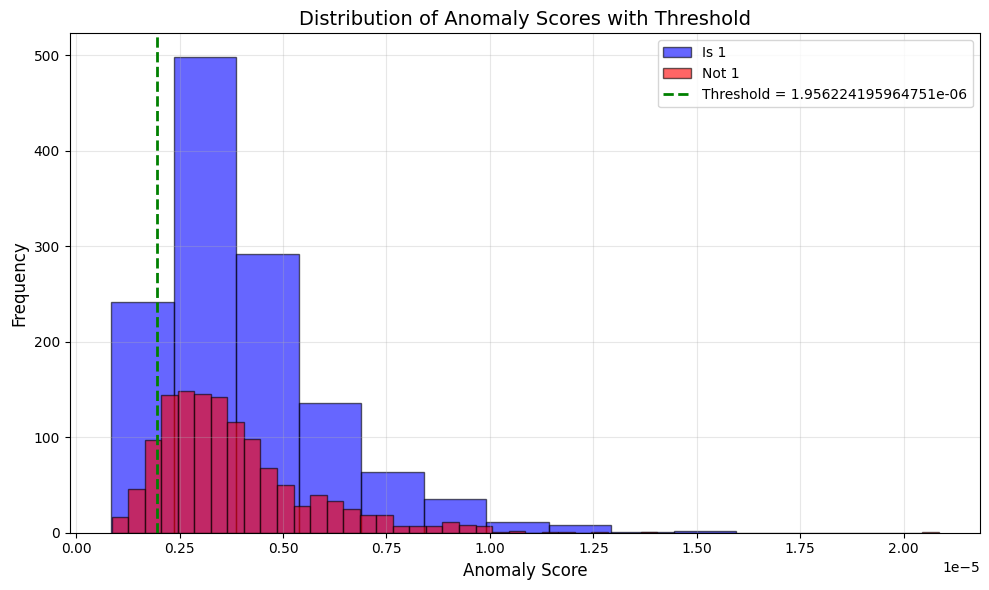

In [39]:
import matplotlib.pyplot as plt

# Create histogram
plt.figure(figsize=(10, 6))

# Plot histograms for normal (0) and anomaly (1) separately
plt.hist(scores[labels == 1], bins=10, alpha=0.6, label='Is 1', color='blue', edgecolor='black')
plt.hist(scores[labels != 1], bins=50, alpha=0.6, label='Not 1', color='red', edgecolor='black')

# Add vertical line for threshold
plt.axvline(x=-best_thresh, color='green', linestyle='--', linewidth=2, label=f'Threshold = {-best_thresh}')

# Labels and title
plt.xlabel('Anomaly Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of Anomaly Scores with Threshold', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
# 40 attributes
def anomaly_scores_full(loader):
  scores = []
  all_attrs = [] 
  model.eval()
  with torch.no_grad():
    for x, y in loader:
      x = x.to(device)
      z = model(x)
      dist = torch.sum((z - c)**2, dim=1)
      scores.extend(dist.cpu().numpy())
      all_attrs.append(y.cpu().numpy())
  return np.array(scores), np.vstack(all_attrs)

Mean Anomaly Score by Attribute:


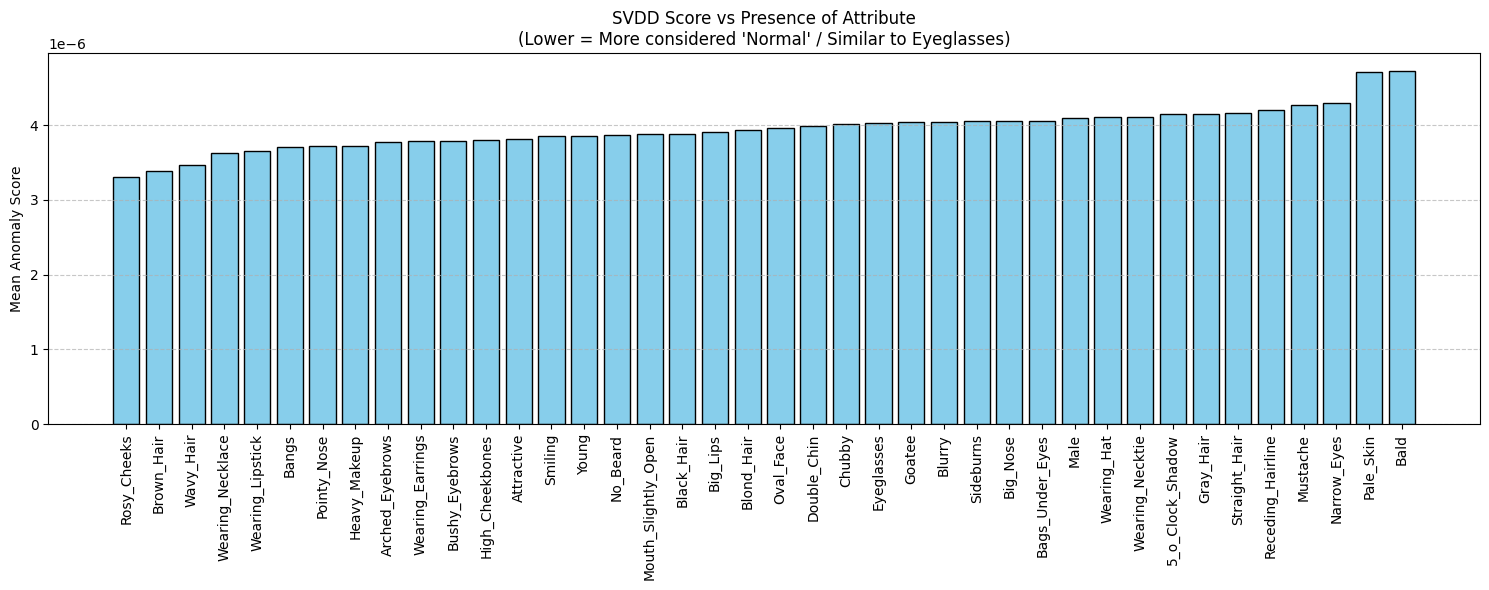

In [41]:
# Get full data
scores_full, full_attrs = anomaly_scores_full(test_loader)
# List of CelebA Attribute Names (Standard Order)
attr_names = [
    "5_o_Clock_Shadow", "Arched_Eyebrows", "Attractive", "Bags_Under_Eyes", "Bald", "Bangs", 
    "Big_Lips", "Big_Nose", "Black_Hair", "Blond_Hair", "Blurry", "Brown_Hair", "Bushy_Eyebrows", 
    "Chubby", "Double_Chin", "Eyeglasses", "Goatee", "Gray_Hair", "Heavy_Makeup", "High_Cheekbones", 
    "Male", "Mouth_Slightly_Open", "Mustache", "Narrow_Eyes", "No_Beard", "Oval_Face", "Pale_Skin", 
    "Pointy_Nose", "Receding_Hairline", "Rosy_Cheeks", "Sideburns", "Smiling", "Straight_Hair", 
    "Wavy_Hair", "Wearing_Earrings", "Wearing_Hat", "Wearing_Lipstick", "Wearing_Necklace", 
    "Wearing_Necktie", "Young"
]
# Calculate mean anomaly score for images possessing each attribute
attr_means = {}
print("Mean Anomaly Score by Attribute:")
for i, name in enumerate(attr_names):
    # Select images that have this attribute (value == 1)
    mask = (full_attrs[:, i] == 1)
    if mask.sum() > 0:
        mean_score = scores_full[mask].mean()
        attr_means[name] = mean_score
        # Optional: Print them
        # print(f"{name}: {mean_score:.6f}")
# Sort by score (ascending)
sorted_attrs = dict(sorted(attr_means.items(), key=lambda item: item[1]))
# Plot
plt.figure(figsize=(15, 6))
plt.bar(sorted_attrs.keys(), sorted_attrs.values(), color='skyblue', edgecolor='black')
plt.xticks(rotation=90)
plt.ylabel("Mean Anomaly Score")
plt.title("SVDD Score vs Presence of Attribute\n(Lower = More considered 'Normal' / Similar to Eyeglasses)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [42]:
torch.save(model.state_dict(), "celeb_svdd.pth")
np.save("center.npy", c.cpu().numpy())
np.save("threshold.npy", np.array([best_thresh]))

# Testing GAN!

In [ ]:
class Generator(nn.Module):
    def __init__(self, ngpu, nc=1, nz=100, ngf=64):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is Z, going into a convolution
            nn.ConvTranspose2d(     nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2,     ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(    ngf,      nc, kernel_size=1, stride=1, padding=2, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output

In [ ]:
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth -O netG.pth

--2025-12-07 11:10:10--  https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth [following]
--2025-12-07 11:10:10--  https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14306386 (14M) [application/octet-stream]
Saving to: ‘netG.pth’

netG.pth            100%[===================>]  13.64M  --.-KB/s    in 0.05s   

2025

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

netG = Generator(ngpu=1, nc=1, nz=100, ngf=64).to(device)

state_dict = torch.load("netG.pth", map_location=device)
netG.load_state_dict(state_dict)
netG.eval()

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 1, kernel_size=(1, 1), stride=(1, 1), padding=(2, 2), bias=False)
    (13): Tanh()
  )
)

In [ ]:
from torch.utils.data import Dataset

class GeneratedDataset(Dataset):
  def __init__(self, images, transform=None):
    self.images = images
    self.transform = transform
  def __len__(self):
    return len(self.images)
  def __getitem__(self, idx):
    img = self.images[idx]
    img = img.squeeze(0).numpy()
    img = Image.fromarray((img * 255).astype('uint8'))
    if self.transform:
      img = self.transform(img)
    return img

In [ ]:
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image
import numpy as np

num_samples = 10000
batch_size = 64
nz = 100

all_images = []
with torch.no_grad():
    for _ in range((num_samples + batch_size - 1) // batch_size):
        current_batch_size = min(batch_size, num_samples - len(all_images))
        z = torch.randn(current_batch_size, nz, 1, 1, device=device)
        fake_images = netG(z)
        all_images.append(fake_images.cpu())

all_images = torch.cat(all_images, dim=0)

transform = transforms.Compose([
    transforms.ToTensor(),
])
super_test_dataset = GeneratedDataset(all_images, transform=transform)
super_test_loader = DataLoader(super_test_dataset, batch_size=batch_size, shuffle=False)

print(f"Super test loader ready with {len(super_test_loader)} batches")

Super test loader ready with 157 batches


In [ ]:
def anomaly_scores(loader):
  scores = []
  model.eval()

  with torch.no_grad():
    for x in loader:
      x = x.to(device)
      z = model(x)
      dist = torch.sum((z - c)**2, dim=1)

      scores.extend(dist.cpu().numpy())

  return np.array(scores)

scores = anomaly_scores(super_test_loader)

In [ ]:
pred_is_1 = (-scores) > best_thresh

In [ ]:
print(pred_is_1.sum())

1699


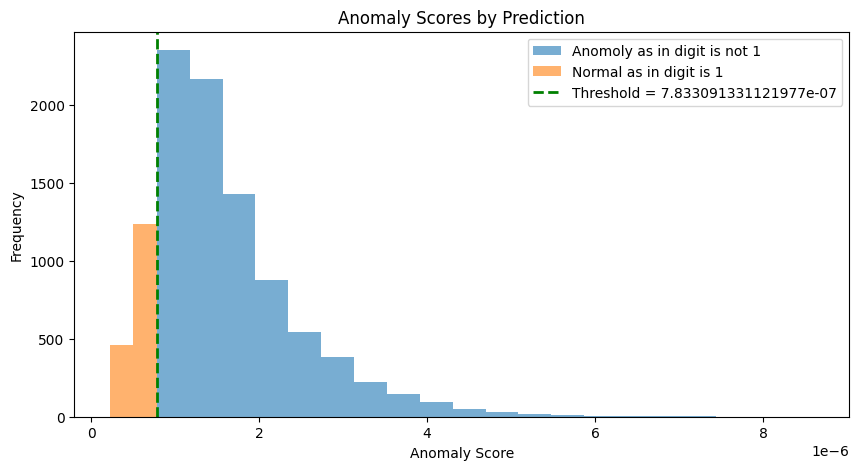

1699
8349


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

pred_is_1 = (-scores) > best_thresh
pred_is_0 = ~pred_is_1

scores_pos = scores[pred_is_1]
scores_neg = scores[pred_is_0]

plt.figure(figsize=(10,5))

plt.hist(scores_neg, bins=20, alpha=0.6, label='Anomoly as in digit is not 1')
plt.hist(scores_pos, bins=2, alpha=0.6, label='Normal as in digit is 1')
plt.axvline(x=-best_thresh, color='green', linestyle='--', linewidth=2, label=f'Threshold = {-best_thresh}')
plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")
plt.title("Anomaly Scores by Prediction")
plt.legend()
plt.show()
print(len(scores_pos))
print(len(scores_neg))

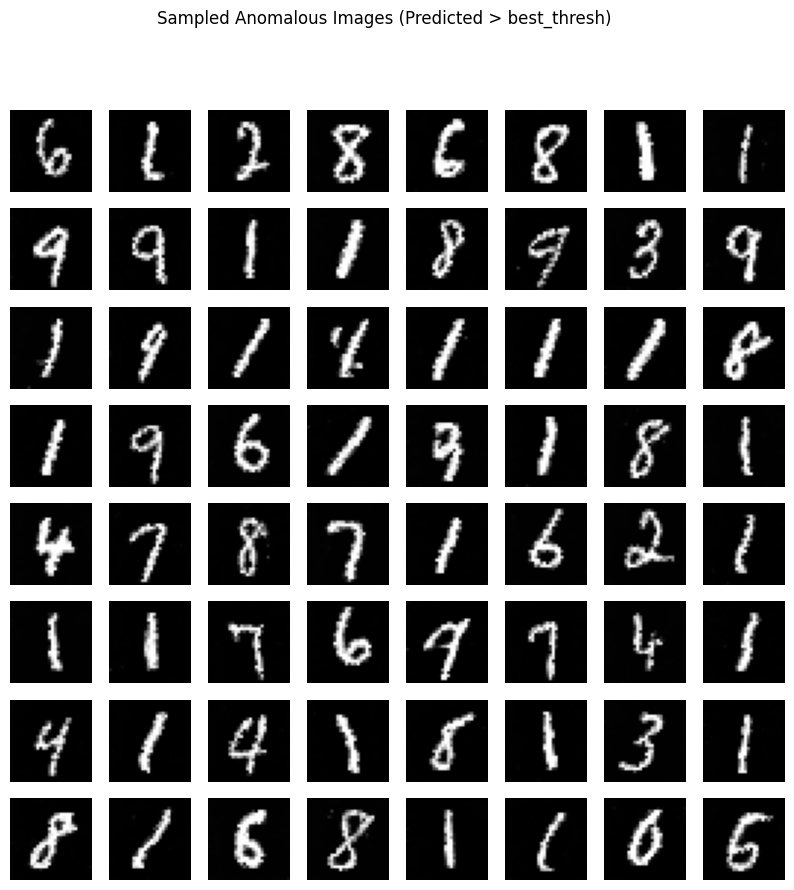

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

pred_is_1 = (-scores) > best_thresh
anomalous_indices = np.where(pred_is_1)[0]

# Sample 64 random indices (or all if fewer than 64)
num_to_sample = min(64, len(anomalous_indices))
sample_indices = np.random.choice(anomalous_indices, num_to_sample, replace=False)

# Collect images corresponding to these indices
anomalous_images = []
all_images_list = []
for batch in super_test_loader:
    if isinstance(batch, list) or isinstance(batch, tuple):
        batch_images = batch[0]  # in case dataset returns tuple
    else:
        batch_images = batch
    all_images_list.append(batch_images)
all_images = torch.cat(all_images_list, dim=0)

sampled_images = all_images[sample_indices]

# Plot sampled images in an 8x8 grid
plt.figure(figsize=(10,10))
for i in range(num_to_sample):
    plt.subplot(8, 8, i+1)
    plt.imshow(sampled_images[i].squeeze().cpu(), cmap='gray')
    plt.axis('off')
plt.suptitle("Sampled Anomalous Images (Predicted > best_thresh)")
plt.show()

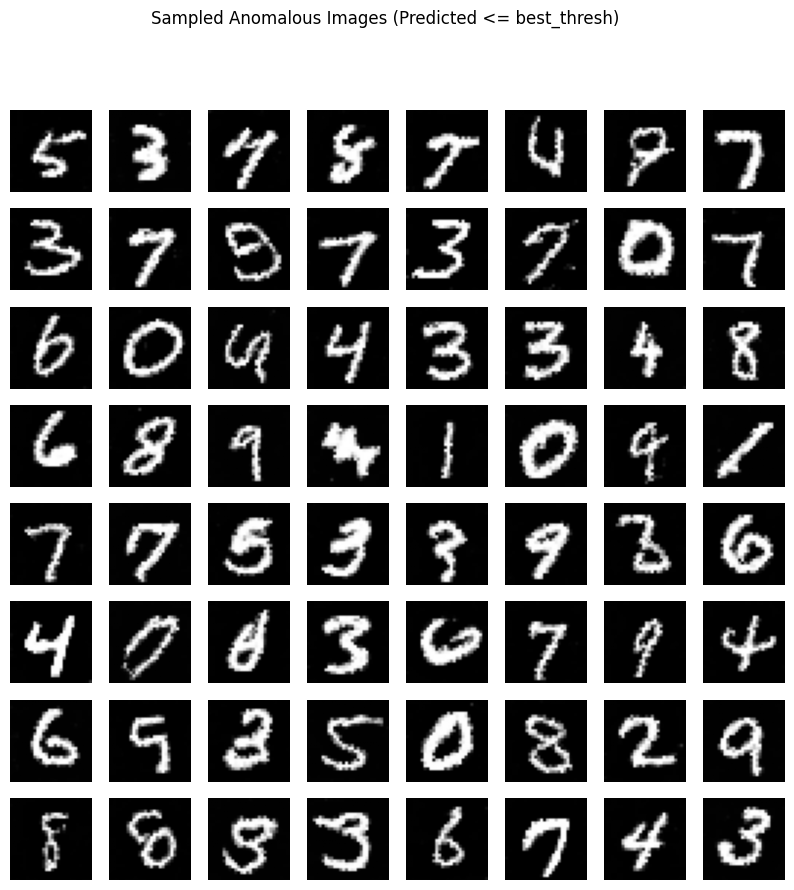

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

pred_is_not_1 = (-scores) <= best_thresh
anomalous_indices = np.where(pred_is_not_1)[0]

# Sample 64 random indices (or all if fewer than 64)
num_to_sample = min(64, len(anomalous_indices))
sample_indices = np.random.choice(anomalous_indices, num_to_sample, replace=False)

# Collect images corresponding to these indices
anomalous_images = []
all_images_list = []
for batch in super_test_loader:
    if isinstance(batch, list) or isinstance(batch, tuple):
        batch_images = batch[0]  # in case dataset returns tuple
    else:
        batch_images = batch
    all_images_list.append(batch_images)
all_images = torch.cat(all_images_list, dim=0)

sampled_images = all_images[sample_indices]

# Plot sampled images in an 8x8 grid
plt.figure(figsize=(10,10))
for i in range(num_to_sample):
    plt.subplot(8, 8, i+1)
    plt.imshow(sampled_images[i].squeeze().cpu(), cmap='gray')
    plt.axis('off')
plt.suptitle("Sampled Anomalous Images (Predicted <= best_thresh)")
plt.show()